# Week 6 — Block 3: Hands-On (Graph & Network Data)

**DATS 6401 · Visualization of Complex Data**

Your turn (~50 min). You'll apply the Block 2 pipeline to a new network: the **Les Misérables co-occurrence graph** — 77 characters, with an edge whenever two characters appear in the same chapter. It ships inside networkx, so no download is needed.

**Tasks:**
1. Load and inspect the network (~6 min)
2. Compute a centrality measure, encode it visually, and compare two layouts (~31 min)
3. Wrap an interactive PyVis network into a Streamlit app (~13 min)

Complete the `# TODO` cells. Hints are provided; the instructor is circulating.

## Task 1 — Load and inspect (~6 min)

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

L = nx.les_miserables_graph()

# TODO: print the number of nodes and edges
# TODO: print the 5 characters with the highest DEGREE
# Hint: dict(L.degree()) and sorted(..., key=..., reverse=True)

print("Nodes:", L.number_of_nodes())
print("Edges:", L.number_of_edges())
print("Degrees:", dict(L.degree()))


Nodes: 77
Edges: 254
Degrees: {'Napoleon': 1, 'Myriel': 10, 'MlleBaptistine': 3, 'MmeMagloire': 3, 'CountessDeLo': 1, 'Geborand': 1, 'Champtercier': 1, 'Cravatte': 1, 'Count': 1, 'OldMan': 1, 'Valjean': 36, 'Labarre': 1, 'Marguerite': 2, 'MmeDeR': 1, 'Isabeau': 1, 'Gervais': 1, 'Listolier': 7, 'Tholomyes': 9, 'Fameuil': 7, 'Blacheville': 7, 'Favourite': 7, 'Dahlia': 7, 'Zephine': 7, 'Fantine': 15, 'MmeThenardier': 11, 'Thenardier': 16, 'Cosette': 11, 'Javert': 17, 'Fauchelevent': 4, 'Bamatabois': 8, 'Perpetue': 2, 'Simplice': 4, 'Scaufflaire': 1, 'Woman1': 2, 'Judge': 6, 'Champmathieu': 6, 'Brevet': 6, 'Chenildieu': 6, 'Cochepaille': 6, 'Pontmercy': 3, 'Boulatruelle': 1, 'Eponine': 11, 'Anzelma': 3, 'Woman2': 3, 'MotherInnocent': 2, 'Gribier': 1, 'MmeBurgon': 2, 'Jondrette': 1, 'Gavroche': 22, 'Gillenormand': 7, 'Magnon': 2, 'MlleGillenormand': 7, 'MmePontmercy': 2, 'MlleVaubois': 1, 'LtGillenormand': 4, 'Marius': 19, 'BaronessT': 2, 'Mabeuf': 11, 'Enjolras': 15, 'Combeferre': 11, 'Pro

**Check yourself:** you should see 77 nodes and 254 edges — and a certain protagonist at the top of the degree list.

## Task 2 — Centrality, encoding, and two layouts (~31 min)

Compute **betweenness centrality**, then draw the network twice — spring layout and circular layout — with:
- node **size** ← betweenness (scale it up, e.g. `value * 2000 + 20`, or sizes will be invisible)
- node **color** ← detected community

In [4]:
from networkx.algorithms.community import greedy_modularity_communities

# TODO: compute betweenness centrality into a dict called `btw`
# TODO: detect communities and build a {node: community_id} dict called `cmap`
#       (see the Block 2 demo for the pattern)
deg = dict(L.degree())

# Betweenness: fraction of shortest paths passing through each node (Brandes' algorithm)
btw = nx.betweenness_centrality(L)

from networkx.algorithms.community import greedy_modularity_communities, modularity
comms = list(greedy_modularity_communities(L))

print("Detected", len(comms), "communities")
print("Modularity Q =", round(modularity(L, comms), 2))
print("Top 3 by degree:     ", sorted(deg, key=deg.get, reverse=True)[:3])
print("Top 3 by betweenness:", sorted(btw, key=btw.get, reverse=True)[:3])

# Map each node to its community id
cmap = {}
for cid, community in enumerate(comms):
    for n in community:
        cmap[n] = cid

Detected 5 communities
Modularity Q = 0.47
Top 3 by degree:      ['Valjean', 'Gavroche', 'Marius']
Top 3 by betweenness: ['Valjean', 'Myriel', 'Gavroche']


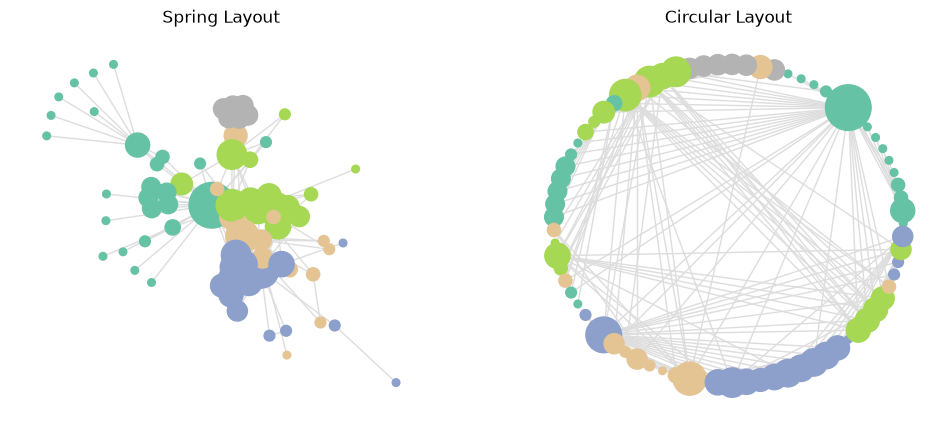

In [8]:
# TODO: draw the network TWICE, side by side:
#   left  = nx.spring_layout(L, seed=42)
#   right = nx.circular_layout(L)
# with node_size from `btw` and node_color from `cmap` in both panels.
# Hint: fig, axes = plt.subplots(1, 2, figsize=(12, 5))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Spring layout
p = nx.spring_layout(L, seed=42)

nx.draw_networkx(
    L, p,
    ax=axes[0],
    with_labels=False,
    node_size=[deg[n] * 30 for n in L.nodes()],
    node_color=[cmap[n] for n in L.nodes()],
    cmap=plt.cm.Set2,
    edge_color="#dddddd"
)

axes[0].set_title("Spring Layout")
axes[0].axis("off")


# Circular layout
r = nx.circular_layout(L)

nx.draw_networkx(
    L, r,
    ax=axes[1],
    with_labels=False,
    node_size=[deg[n] * 30 for n in L.nodes()],
    node_color=[cmap[n] for n in L.nodes()],
    cmap=plt.cm.Set2,
    edge_color="#dddddd"
)

axes[1].set_title("Circular Layout")
axes[1].axis("off")

plt.show()


**Discuss with your neighbor** (we'll surface these in Block 4):

1. Which characters are the *bridges* (high betweenness), and does that match your memory of the story?
2. Which layout reveals the community structure — and what is the circular layout *better* at showing?
3. The spring layout puts some characters close together who share no edge. What does that distance mean — and what does it *not* mean?

## Task 3 — Interactive network in Streamlit (~13 min)

A static drawing of 77 nodes is already crowded. Interaction (zoom, drag, hover) is the escape hatch.

1. Open `app_starter.py` (in this folder) and skim it — it loads Les Mis, filters by degree, and renders a PyVis network with a layout selector.
2. In a terminal: `streamlit run app_starter.py`
3. Play with the controls, then pick **one** TODO at the bottom of the file and implement it.

The cell below previews the PyVis object right here in the notebook first:

In [ ]:
from pyvis.network import Network

net = Network(height="500px", width="100%", cdn_resources="in_line", notebook=False)
net.from_nx(L)
net.save_graph("lesmis_preview.html")
print("Wrote lesmis_preview.html — open it in your browser for the interactive view.")

## Before you leave

- Make sure your two-layout figure renders and your `app_starter.py` runs.
- Homework (full spec in the Week 6 chapter of the course book): build a **network-explorer Streamlit app** on a dataset of your choice — at least two structural encodings and one meaningful interactive control. The starter app is a legitimate starting point; extending it is encouraged.